In [1]:
# General Imports
import sys
from pathlib import Path
import pickle
from scipy.optimize import curve_fit
import numpy as np
from matplotlib.axes import Axes
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import RegularPolygon
import matplotlib.pyplot as plt

# Add project root
project_root = Path.cwd().parents[1]
sys.path.append(str(project_root))

# Internal Imports
from main import model, methods, tools, honeycomb_specific
from workflows import data_creation

# Data Path
RAW_DATA_PATH = Path("data/raw")
PROCESSED_DATA_PATH = Path("data/processed")
FIGURES_DATA_PATH = Path("data/figures")

# Colors
Cs = tools.visualization.Colors
colors = [Cs.RED, Cs.GREEN, Cs.BLUE]

# Metric conversion
cm = 1/2.54

[INFO] TensorNetwork backend set to 'jax'.


### Data Loader

In [2]:
def get_raw_data(file_name):
    file_path = RAW_DATA_PATH / file_name
    with open(file_path, "rb") as f:
        data = pickle.load(f)
    return data

def get_processed_correlations(m_ref, L, num_of_extra_particles, num_of_excitations, is_spin_ice=False):
    file_name = f"Correlations"
    if is_spin_ice:
        file_name += "_HonSpinIce"
    if num_of_extra_particles >= 0:
        file_name += f"_{m_ref}m_ref_{L}L_{num_of_extra_particles}num_of_extra_particles"
    else:
        file_name += f"_{m_ref}m_ref_{L}L_m{abs(num_of_extra_particles)}num_of_extra_particles"
    file_name += f"_{num_of_excitations}num_of_excitations.pkl"
    file_path = PROCESSED_DATA_PATH / file_name
    with open(file_path, "rb") as f:
        data = pickle.load(f)
    return data

def get_structure_factor(m_ref, L, num_of_extra_particles, num_of_excitations, is_spin_ice=False):
    file_name = "StructureFactor"
    if is_spin_ice:
        file_name += "_HonSpinIce"
    if num_of_extra_particles >= 0:
        file_name += f"_{m_ref}m_ref_{L}L_{num_of_extra_particles}num_of_extra_particles"
    else:
        file_name += f"_{m_ref}m_ref_{L}L_m{abs(num_of_extra_particles)}num_of_extra_particles"
    file_name += f"_{num_of_excitations}num_of_excitations.pkl"
    file_path = PROCESSED_DATA_PATH / file_name
    with open(file_path, "rb") as f:
        data = pickle.load(f)
    return data

### Quasi-Particle Denisty

In [3]:
def get_mean_QP_density(L, num_of_extra_particles, num_of_excitations):
    assert num_of_extra_particles == 0 or num_of_excitations == 0
    area_to_explore = L**2/3 # each QP stays on its partition (encluding 1/3 of all plaquettes)
    if num_of_extra_particles != 0:
        assert num_of_extra_particles in [-2,1,2]
        # creates 3 QP per extra particle, which each live on one partition
        n_QP_mean = (abs(num_of_extra_particles))/area_to_explore
    elif num_of_excitations != 0:
        assert num_of_excitations == 1
        # creates 2 QP per excitation, which both live on one partition
        n_QP_mean = (2*num_of_excitations)/area_to_explore
    else:
        n_QP_mean = None
    return n_QP_mean

# Correlations Plotter

In [16]:
QP_m_size = 4
QP_markers = [
    dict(marker="+", markersize=QP_m_size+2, markeredgewidth=0.75),
    dict(marker="x", markersize=QP_m_size, markeredgewidth=0.75)]
field_m_size = 5
field_markers = [
    dict(marker=".", markersize=field_m_size, markeredgewidth=0.5, markeredgecolor=tools.visualization.Colors.BLACK),
    dict(marker="v", markersize=field_m_size, markeredgewidth=0.5, markeredgecolor=tools.visualization.Colors.BLACK),
    dict(marker="^", markersize=field_m_size, markeredgewidth=0.5, markeredgecolor=tools.visualization.Colors.BLACK),
    dict(marker="*", markersize=field_m_size, markeredgewidth=0.5, markeredgecolor=tools.visualization.Colors.BLACK)]
err_bar_style = dict(zorder=0, ecolor="gray", linestyle="none", capsize=1, elinewidth=0.8)

Ls_colors = {"36":Cs.DARKGRAY, "60":Cs.GREEN, "84":Cs.BLUE, "108":Cs.RED}
TEXT_STYLE = dict(color=Cs.BLACK, fontsize=10)
FIT_LINE_STYLE = dict(zorder=40, ls="-", lw=.75, color=Cs.BLACK)
FIT_EXTRAPOLATED_LINE_STYLE = dict(zorder=40, ls="--", lw=.75, color=Cs.GRAY)
LEGEND_MARKER_STYLE_CORRS = dict(marker='s', linestyle='none', markersize=7, markeredgewidth=0.75, markeredgecolor=Cs.BLACK)

def power_law(r, A, a):
    return A * r**(a)

def plt_correlations(
        defects:list[int], m_ref:int, is_spin_ice:bool=False, Ls:list[int]=[36,60,84,108], ax:Axes=None,
        sub_ids_to_plot:list[int]=None, set_title:bool=False, set_x_axis:bool=False, set_y_axis:bool=False,
        place_legend:bool=False, symlog:bool=False
):
    
    # Init figure
    if ax is None:
        tools.visualization.setup_matplotlib_style()
        fig, ax = plt.subplots(figsize=(15*cm, 7*cm))
        ax_given = False
    else:
        ax_given = True
    
    if defects == [0,0]:
        plot_field = True
    else: # plot quasi-particle correlations
        plot_field = False
    
    if symlog:
        assert plot_field

    for L_ind, L in enumerate(Ls):
        is_last_L = (L_ind==len(Ls)-1)

        # Get data
        data = get_processed_correlations(m_ref, L, defects[0], defects[1], is_spin_ice)
        if plot_field:
            r_period = 4
            labels = [r"part. $a_1$", r"part. $b_1$", r"part. $a_2$", r"part. $b_2$"]
            markers = field_markers

            if is_spin_ice:
                C_field_r = data["C_field_r"][0]
                eps_C_field_r = data["eps_C_field_r"][0]
            else:
                C_field_r = data["C_field_r"]
                eps_C_field_r = data["eps_C_field_r"]
            
            if symlog:
                x_lim = [1, 70]
            else:
                x_lim = [7e-1, 200]

            C_field_r_conn = C_field_r-(m_ref/6)**2
            if symlog:
                C_field_r_conn_abs = C_field_r_conn
            else:
                C_field_r_conn_abs = np.abs(C_field_r_conn)
            if is_spin_ice:
                num_of_data_points = int(C_field_r_conn_abs.shape[0]//4*0.8)
            else:
                num_of_data_points = C_field_r_conn_abs.shape[0]//4
            Cr, eps_Cr = C_field_r_conn_abs[:num_of_data_points], eps_C_field_r[:num_of_data_points]
            r_axis_scale = 1 #np.cos(np.pi/6)/2 # distance between two sites of the same partition (4 steps): 2*np.cos(30)
            rs = np.arange(0, num_of_data_points, dtype=np.float64)*r_axis_scale
        else:
            r_period = 2
            labels = ["same color", "different color"]
            markers = QP_markers

            x_lim = [7e-3, 2.5e-1]
            n_QP_mean = get_mean_QP_density(L, defects[0], defects[1])
            C_QP_r = (data["C_QP_r"])
            eps_C_QP_r = (data["eps_C_QP_r"])
            C_QP_r_rescaled = C_QP_r/n_QP_mean**2
            eps_C_QP_r_rescaled = eps_C_QP_r/n_QP_mean**2
            num_of_data_points = C_QP_r_rescaled.shape[0]//6
            Cr, eps_Cr = C_QP_r_rescaled[:num_of_data_points], eps_C_QP_r_rescaled[:num_of_data_points]
            r_axis_scale = np.cos(np.pi/6) # distance between two plaquettes of the same partition (2 steps): 2*np.cos(30)
            rs = np.arange(0, num_of_data_points, dtype=np.float64)*r_axis_scale

            # Conformally mapped distances
            L_eff = 2*np.cos(np.pi/6)*L # length until we reach the same point again (diagonal cut through the system)
            rs = np.sin(np.pi*np.array(rs)/L_eff)/np.pi

        # Parameters for fitting
        if plot_field:
            fit_start_ind, fit_end_ind = 2, -1
            if is_spin_ice:
                sub_ids_to_fit=[1]
            else:
                sub_ids_to_fit=[1]
            if symlog and not (m_ref == 1 and is_spin_ice):
                sub_ids_to_fit.append(3)
                    
        elif defects == [1,0]:
            sub_ids_to_fit=[1]
            fit_start_ind, fit_end_ind = 2, -1
        elif defects == [2,0]:
            sub_ids_to_fit=[0,1]
            fit_start_ind, fit_end_ind = 2, -1
        elif defects == [0,1]:
            sub_ids_to_fit=[0]
            if m_ref == 1:
                fit_start_ind, fit_end_ind = 4, -1
            else:
                fit_start_ind, fit_end_ind = 3, -1

        # Filter sub datasets
        if r_period is None:
            rs_subs, Cr_subs, eps_Cr_subs = [rs], [Cr], [eps_Cr]
            if is_last_L and len(sub_ids_to_fit)!=0:
                fit_subs = [True]
            else:
                fit_subs = [False]
        else:
            rs_subs, Cr_subs, eps_Cr_subs = [], [], []
            fit_subs = []
            for sub_id in range(r_period):
                if sub_ids_to_plot is None or sub_id in sub_ids_to_plot:
                    rs_subs.append([])
                    Cr_subs.append([])
                    eps_Cr_subs.append([])
                    for i in range(len(rs)):
                        if i%r_period==sub_id:
                            rs_subs[-1].append(rs[i])
                            Cr_subs[-1].append(Cr[i])
                            if eps_Cr[i] is not None:
                                eps_Cr_subs[-1].append(eps_Cr[i])
                            else:
                                eps_Cr_subs[-1].append(None)
                    if is_last_L and sub_id in sub_ids_to_fit:
                        fit_subs.append(True)
                    else:
                        fit_subs.append(False)

        # Plot dataset
        for i in range(len(rs_subs)):
            rs, Cr, eps_Cr = rs_subs[i], Cr_subs[i], eps_Cr_subs[i]
            if not plot_field:
                eps_Cr = None
            
            # Plot full data
            ax.plot(rs, Cr, color=Ls_colors[str(L)], **markers[i % len(markers)], linestyle='none')

            # Plot error bars only on filtered points
            if eps_Cr is not None:
                # Errorbar mask
                rs = np.array(rs)
                Cr = np.array(Cr)
                eps_Cr = np.array(eps_Cr)
                mask_every3 = np.arange(len(rs)) % 3 == 0 # only every 3rd point
                mask_large_err = eps_Cr >= 0.02 * np.abs(Cr) # error > 2% of value
                mask = mask_every3 & mask_large_err
                ax.errorbar(
                    rs[mask], Cr[mask], yerr=eps_Cr[mask], color=Ls_colors[str(L)],
                    **markers[i % len(markers)], **err_bar_style)

        # Fit curve
        fit_count = 0
        for i in range(len(rs_subs)):
            if fit_subs[i]:
                rs, Cr = rs_subs[i], Cr_subs[i]
                if is_spin_ice and m_ref == 1:
                    Cr = np.array(Cr)
                    rs = np.array(rs)

                    mask = np.abs(Cr) >= 1e-4
                    Cr = Cr[mask]
                    rs = rs[mask]
                popt, pcov = curve_fit(
                    power_law, rs[fit_start_ind:fit_end_ind], Cr[fit_start_ind:fit_end_ind], p0=(1.0, -1.0))
                A_fit, a_fit = popt
                r_fit = np.linspace(x_lim[0], rs[fit_start_ind], 1000)
                ax.plot(
                    r_fit, power_law(r_fit, A_fit, a_fit), **FIT_EXTRAPOLATED_LINE_STYLE)
                r_fit = np.linspace(rs[fit_start_ind], rs[fit_end_ind], 1000)
                ax.plot(
                    r_fit, power_law(r_fit, A_fit, a_fit), **FIT_LINE_STYLE)
                r_fit = np.linspace(rs[fit_end_ind], x_lim[1], 1000)
                ax.plot(
                    r_fit, power_law(r_fit, A_fit, a_fit), **FIT_EXTRAPOLATED_LINE_STYLE)

                if symlog and (m_ref == 1 and is_spin_ice):
                    r_fit = np.linspace(x_lim[0], x_lim[1], 1000)
                    ax.plot(
                        r_fit, -power_law(r_fit, A_fit, a_fit), **FIT_EXTRAPOLATED_LINE_STYLE)
                
                if plot_field:
                    xt = 10
                    y_fac = 2
                else:
                    y_fac = 1.1
                if (fit_count==0 and defects!=[2,0]) or (fit_count==1 and defects==[2,0]):
                    if not plot_field:
                        xt = 0.03
                    yt = power_law(xt, A_fit, a_fit)*y_fac
                    ha = "left"
                else:
                    if not plot_field:
                        xt = 0.08
                    yt = power_law(xt, A_fit, a_fit)*y_fac
                    ha = "right"
                ax.text(
                    xt, yt, rf"${a_fit:.2f}$",
                    ha=ha, va="bottom", **TEXT_STYLE)
                fit_count += 1

    # Layout
    if set_title:
        ax.set_title(rf"$m={m_ref}$", fontsize=ax.xaxis.label.get_size(), fontweight="normal")
    if set_x_axis:
        # x lim
        ax.set_xlim(x_lim)
        ax.set_xscale("log")
        
        # x label
        if plot_field:
            ax.set_xlabel(r"$d$")
        else:
            pass #ax.set_xlabel(r"$\tilde{r}/L_\mathrm{eff}$")
    
    if set_y_axis:

        # y lim
        if plot_field:
            if symlog:
                ax.set_ylim([-5e-1, 5e-1])
            else:
                ax.set_ylim([5e-6, 5e-1])

        elif defects == [1,0]:
            ax.set_ylim([8e-1, 2.5e0])
        elif defects == [2,0]:
            ax.set_ylim([1.5e-1, 2.5e0])
        elif defects == [0,1]:
            ax.set_ylim([4.5e-1, 2.5e0])

        if symlog:
            ax.set_yscale("symlog", linthresh=2e-5)
        else:
            ax.set_yscale("log")
        ax.minorticks_on()

        # y ticks
        if defects == [2,0]:
            ax.set_yticks([1e0], [r"$10^{0}$"])
            ax.set_yticks(
                [2e-1, 3e-1, 4e-1, 5e-1, 6e-1, 7e-1, 8e-1, 9e-1, 2e0],
                [r"$2\times 10^{-1}$", None, None, None, None, None, None, None, r"$2\times 10^{0}$"], minor = True)
        elif defects == [0,1]:
            ax.set_yticks([1e0], [r"$10^{0}$"])
            ax.set_yticks(
                [5e-1, 6e-1, 7e-1, 8e-1, 9e-1, 2e0], 
                [r"$5\times 10^{-1}$", None, None, None, None, r"$2\times 10^{0}$"], minor = True)

        # y label
        if plot_field:
            if symlog:
                ax.set_ylabel(
                    r"$C_{\mathrm{field}}(d)"+
                    fr"-\left(\frac{m_ref}{6}\right)^2$")
            else:
                ax.set_ylabel(
                    r"$\left|C_{\mathrm{field}}(d)"+
                    r"-\left(\frac{m}{6}\right)^2\right|$")
        else:
            pass #ax.set_ylabel(r"$C_{\mathrm{QP}}(\tilde{r}/L_\mathrm{eff}) \, / \, \langle n_{\mathrm{QP}} \rangle^2$")
    
    # Legend
    if place_legend:
        legend_handles = []
        for i, L in enumerate(Ls):
            label = rf"$L={L}$"
            color = Ls_colors[str(L)]
            legend_handles.append(
                Line2D(
                    [0], [0], markerfacecolor=color, label=label, **LEGEND_MARKER_STYLE_CORRS))
        
        for style, label in zip(markers, labels):
            legend_handles.append(
                Line2D(
                    [0], [0],
                    color='gray', label=label, linestyle='none', **style))
        ax.legend(
            handles=legend_handles, handletextpad=0.1, loc="center left", frameon=False,
            prop={'size': 9})

    ax.tick_params(which='both', direction='in')
    
    if not ax_given:
        fig.tight_layout()
        
    return ax

# Structure Factor Plotter

In [8]:
CMAP = plt.cm.viridis
CBAR_VMIN, CBAR_VMAX = 0, 0.5
BZ_STYLE = dict(color=Cs.WHITE, lw=.5, ls="-", alpha=.75, solid_capstyle="round")
TEXT_STYLE_HSP = dict(color=Cs.WHITE, fontsize=9)


def plt_BZ_without_corners(ax, radius, orientation=0., gap=0.1, **kwargs):
    if gap == 0:
        kwargs.pop("solid_capstyle")
        kwargs["edgecolor"] = kwargs.pop("color")
        kwargs["facecolor"] = Cs.NONE
        BZ = RegularPolygon(
            (0, 0), numVertices=6, radius=radius, 
            orientation=orientation, **kwargs)
        ax.add_patch(BZ)
    else:
        theta = np.linspace(0, 2*np.pi, 7) + orientation + np.pi/2
        x = radius * np.cos(theta)
        y = radius * np.sin(theta)
        for i in range(6):
            x0, y0 = x[i], y[i]
            x1, y1 = x[i+1], y[i+1]
            dx = x1 - x0
            dy = y1 - y0
            x_start = x0 + dx*gap
            y_start = y0 + dy*gap
            x_end = x1 - dx*gap
            y_end = y1 - dy*gap
            ax.plot([x_start, x_end], [y_start, y_end], **kwargs)


def plt_structure_factor(
        defects:list[int], m_ref:int, is_spin_ice:bool=False, L:int=60, ax:Axes=None,
        set_title:bool=False, set_x_axis:bool=False, set_y_axis:bool=False, rescale_Sq:bool=False,
):
    # Init figure
    if ax is None:
        tools.visualization.setup_matplotlib_style()
        fig, ax = plt.subplots(figsize=(10*cm, 10*cm))
        ax_given = False
    else:
        ax_given = True
    
    # Get data
    data = get_structure_factor(m_ref, L, defects[0], defects[1], is_spin_ice=is_spin_ice)
    Sq_grid = data["Sq_grid"]
    qx, qy = data["qx"], data["qy"]
    Sq_max = np.max(Sq_grid)
    f = CBAR_VMAX/Sq_max
    if rescale_Sq:
        Sq_grid *= f
    print(f"m={defects}, L={L}, is_spin_ice={is_spin_ice} with Sq_max={round(Sq_max,3)} f={round(f,3)}")

    # Plot data
    xlabel, ylabel = None, None
    if set_x_axis:
        xlabel=r"$\pi k_x$"
    if set_y_axis:
        ylabel=r"$\pi k_y$"
    ax = tools.visualization.plt_structure_factor(
        Sq_grid, qx, qy, kx_lim=[-3.25*np.pi, 3.25*np.pi], ky_lim=[-3.25*np.pi, 3.25*np.pi], ax=ax,
        vmax_cbar=CBAR_VMAX, add_colorbar=False, xlabel=xlabel, ylabel=ylabel, tick_spacing=np.pi)

    # BZ's
    Kx = 4/3*np.pi
    plt_BZ_without_corners(ax, Kx, orientation=np.pi/6, gap=0.05, **BZ_STYLE)
    plt_BZ_without_corners(ax, 4/np.sqrt(3)*np.pi, orientation=0, gap=0., **BZ_STYLE)
    ax.text(Kx-0.8, 0, r"$K$", ha="right", va="center", **TEXT_STYLE_HSP)

    # Layout
    if set_title:
        ax.set_title(rf"$m={m_ref}$", fontsize=ax.xaxis.label.get_size(), fontweight="normal")

    if not ax_given:
        fig.tight_layout()

    return ax

# Field

In [9]:
LEGEND_MARKER_STYLE = dict(marker='s', linestyle='none', markersize=7, markeredgewidth=0.75, markeredgecolor=Cs.BLACK)


def plt_field(fig, ax, defects, Ls, is_spin_ice=False, set_title=True, rescale_Sq=False):
    for row in range(2):
        ax[row, 1].sharey(ax[row, 0])
        ax[row, 2].sharey(ax[row, 0])
        for col in [1, 2]:
            ax[row, col].tick_params(labelleft=False)

    plt_correlations(defects=defects, m_ref=1, is_spin_ice=is_spin_ice, Ls=Ls, ax=ax[0, 0], set_title=set_title, set_x_axis=True, set_y_axis=True)
    plt_correlations(defects=defects, m_ref=2, is_spin_ice=is_spin_ice, Ls=Ls, ax=ax[0, 1], set_title=set_title, set_x_axis=True)
    plt_correlations(defects=defects, m_ref=3, is_spin_ice=is_spin_ice, Ls=Ls, ax=ax[0, 2], set_title=set_title, set_x_axis=True)

    plt_structure_factor(
        defects=defects, m_ref=1, is_spin_ice=is_spin_ice, L=60, ax=ax[1, 0], set_x_axis=True, set_y_axis=True, rescale_Sq=rescale_Sq)
    plt_structure_factor(
        defects=defects, m_ref=2, is_spin_ice=is_spin_ice, L=60, ax=ax[1, 1], set_x_axis=True, rescale_Sq=rescale_Sq)
    plt_structure_factor(
        defects=defects, m_ref=3, is_spin_ice=is_spin_ice, L=60, ax=ax[1, 2], set_x_axis=True, rescale_Sq=rescale_Sq)

    # Correlations Legend
    ax[0, 3].axis("off")
    legend_handles = []
    for i, L in enumerate(Ls):
        label = rf"$L={L}$"
        color = Ls_colors[str(L)]
        legend_handles.append(
            Line2D(
                [0], [0], markerfacecolor=color, label=label, **LEGEND_MARKER_STYLE))
    labels = [r"part. $A_1$", r"part. $B_1$", r"part. $A_2$", r"part. $B_2$"]
    for style, label in zip(field_markers, labels):
        legend_handles.append(
            Line2D(
                [0], [0],
                linestyle='none',color='gray',label=label,**style))
    ax[0, 3].legend(
        handles=legend_handles, bbox_to_anchor=(-0.1, 1.0), handletextpad=0.1, loc="upper left", frameon=False,
        prop={'size': 9})

    # Structure Factor cbar
    ax[1, 3].axis("off")
    sm = ScalarMappable(cmap=CMAP, norm=Normalize(vmin=CBAR_VMIN, vmax=CBAR_VMAX))
    sm.set_array([])
    pos = ax[1, 3].get_position()
    new_cax_pos = [pos.x0+0.1*pos.width, pos.y0+0.03*pos.height, pos.width*0.15, pos.height*0.94]
    cbar_ax = fig.add_axes(new_cax_pos)
    cbar = fig.colorbar(sm, cax=cbar_ax, location="right", label=r"$S(\mathbf{k})$")
    cbar.set_ticks([0, 0.1, 0.2, 0.3, 0.4,  0.5])
    return fig, ax

m=[0, 0], L=60, is_spin_ice=False with Sq_max=0.481 f=1.039
m=[0, 0], L=60, is_spin_ice=False with Sq_max=0.485 f=1.032
m=[0, 0], L=60, is_spin_ice=False with Sq_max=0.473 f=1.056
m=[0, 0], L=60, is_spin_ice=True with Sq_max=0.432 f=1.156
m=[0, 0], L=60, is_spin_ice=True with Sq_max=0.396 f=1.263
m=[0, 0], L=60, is_spin_ice=True with Sq_max=0.445 f=1.124


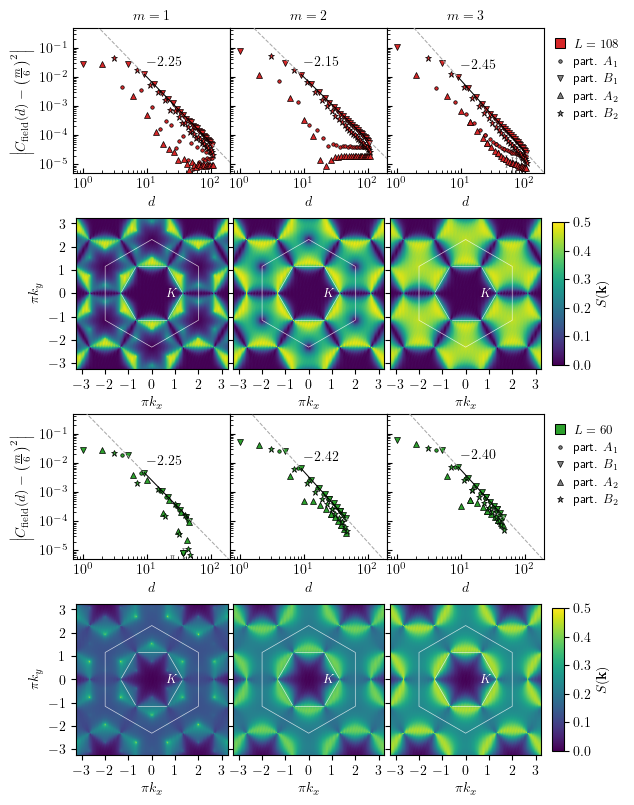

In [10]:
Ls = [108]
Ls_SI = [60]
defects = [0,0]

tools.visualization.setup_matplotlib_style()
fig, ax = plt.subplots(
    4, 4, figsize=(18*cm, 2*12*cm), height_ratios=(0.96, 1, 0.96, 1), width_ratios=(1, 1, 1, 0.5))
ax = np.array(ax)

fig.subplots_adjust(wspace=0)
fig.subplots_adjust(hspace=0.3)

fig, ax[0:2,:] = plt_field(fig, ax[0:2,:], defects, Ls=Ls)
fig, ax[2:,:] = plt_field(fig, ax[2:,:], defects, Ls=Ls_SI, is_spin_ice=True, set_title=False, rescale_Sq=False)

file_name = f"Field_Corrs"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
fig.show()

# Field (larger plot)

In [11]:
LEGEND_MARKER_STYLE = dict(marker='s', linestyle='none', markersize=7, markeredgewidth=0.75, markeredgecolor=Cs.BLACK)

def plt_field_correlations_large(Ls, is_spin_ice=False):
    tools.visualization.setup_matplotlib_style()
    fig, ax = plt.subplots(
        3, 1, figsize=(18*cm, 20*cm), sharex="col")
    ax = np.array(ax)
    fig.subplots_adjust(wspace=0)
    fig.subplots_adjust(hspace=0)

    plt_correlations(ax=ax[0], defects=[0,0], m_ref=1, Ls=Ls, set_x_axis=False, set_y_axis=True, is_spin_ice=is_spin_ice, symlog=True)
    plt_correlations(ax=ax[1], defects=[0,0], m_ref=2, Ls=Ls, set_x_axis=False, set_y_axis=True, is_spin_ice=is_spin_ice, symlog=True)
    plt_correlations(ax=ax[2], defects=[0,0], m_ref=3, Ls=Ls, set_x_axis=True, set_y_axis=True, is_spin_ice=is_spin_ice, symlog=True)

    # Correlations Legend
    legend_handles = []
    for i, L in enumerate(Ls):
        label = rf"$L={L}$"
        color = Ls_colors[str(L)]
        legend_handles.append(
            Line2D(
                [0], [0], markerfacecolor=color, label=label, **LEGEND_MARKER_STYLE))
    labels = [r"part. $A_1$", r"part. $B_1$", r"part. $A_2$", r"part. $B_2$"]
    for style, label in zip(field_markers, labels):
        legend_handles.append(
            Line2D(
                [0], [0],
                linestyle='none',color='gray',label=label,**style))
    ax[0].legend(
        handles=legend_handles, loc="center left", frameon=False, prop={'size': 9})
    return fig, ax

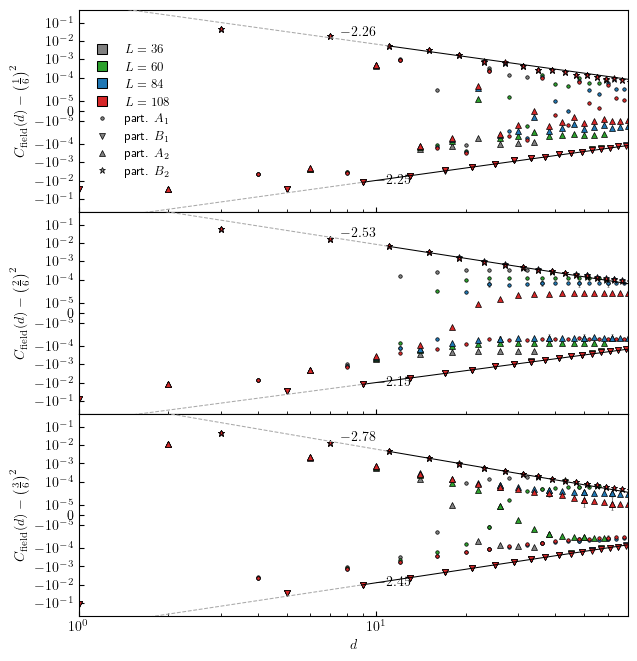

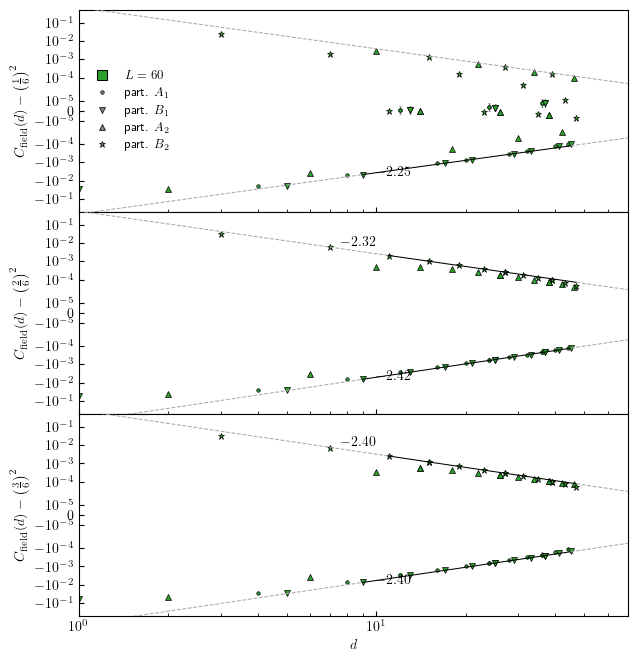

In [12]:
fig, ax = plt_field_correlations_large([36, 60, 84, 108], is_spin_ice=False)
file_name = f"Field_Corrs_large"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
fig.show()

fig, ax = plt_field_correlations_large([60], is_spin_ice=True)
file_name = f"SI_Field_Corrs_large"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
fig.show()

# Quasi Particles

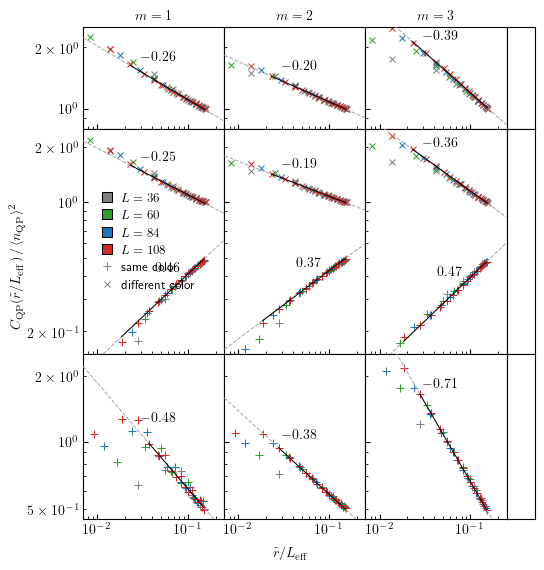

In [17]:
Ls = [36, 60, 84, 108]

tools.visualization.setup_matplotlib_style()
fig, ax = plt.subplots(
    3, 4, figsize=(15.5*cm, 16*cm), sharey="row", sharex="col", 
    height_ratios=(0.45, 1, 0.73), width_ratios=(1,1,1,0.2))
for row in range(3):
    ax[row, 3].tick_params(axis='both', which='both', length=0, labelbottom=False, labelleft=False)
fig.subplots_adjust(left=0.16, bottom=0.10, wspace=0.0, hspace=0.0)

defects = [1,0]
plt_correlations(defects=defects, m_ref=1, Ls=Ls, ax=ax[0, 0], set_title=True, set_y_axis=True)
plt_correlations(defects=defects, m_ref=2, Ls=Ls, ax=ax[0, 1], set_title=True)
plt_correlations(defects=defects, m_ref=3, Ls=Ls, ax=ax[0, 2], set_title=True)

defects = [2,0]
plt_correlations(defects=defects, m_ref=1, Ls=Ls, ax=ax[1, 0], set_y_axis=True, place_legend=True)
plt_correlations(defects=defects, m_ref=2, Ls=Ls, ax=ax[1, 1])
plt_correlations(defects=defects, m_ref=3, Ls=Ls, ax=ax[1, 2])

defects = [0,1]
plt_correlations(defects=defects, m_ref=1, Ls=Ls, ax=ax[2, 0], set_x_axis=True, set_y_axis=True)
plt_correlations(defects=defects, m_ref=2, Ls=Ls, ax=ax[2, 1], set_x_axis=True)
plt_correlations(defects=defects, m_ref=3, Ls=Ls, ax=ax[2, 2], set_x_axis=True)

fig.text(
    0.04, 0.5, r"$C_{\mathrm{QP}}(\tilde{r}/L_\mathrm{eff}) \, / \, \langle n_{\mathrm{QP}} \rangle^2$",
    va="center", rotation="vertical")
fig.text(0.5, 0.04, r"$\tilde{r}/L_\mathrm{eff}$", ha="center")

file_name = f"QP_Corrs"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
fig.show()


### Structure Factor Pinch Point

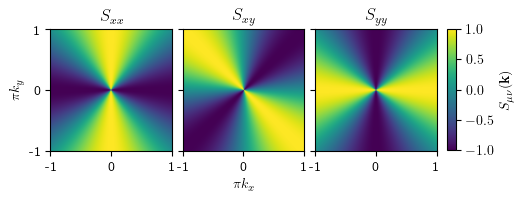

In [14]:
tools.visualization.setup_matplotlib_style()

fig, axes = plt.subplots(
    1, 4, figsize=(15*cm, 5*cm), width_ratios=(1, 1, 1, 0.5), sharey=True)
fig.subplots_adjust(wspace=0.1)


n = 400
qx = np.linspace(-np.pi*1.1, np.pi*1.1, n)
qy = np.linspace(-np.pi*1.1, np.pi*1.1, n)
QX, QY = np.meshgrid(qx, qy)
Q2 = QX**2 + QY**2
eps = 1e-12
Q2 = np.where(Q2 == 0, eps, Q2)
S_xx = 1 - (QX**2) / Q2
S_xy = - (QX * QY) / Q2
S_yy = 1 - (QY**2) / Q2

im0 = axes[0].imshow(S_xx, extent=[-np.pi, np.pi, -np.pi, np.pi],
                     origin='lower', cmap='viridis')
axes[0].set_title(r"$S_{xx}$")
im1 = axes[1].imshow(S_xy, extent=[-np.pi, np.pi, -np.pi, np.pi],
                     origin='lower', cmap='viridis')
axes[1].set_title(r"$S_{xy}$")
im2 = axes[2].imshow(S_yy, extent=[-np.pi, np.pi, -np.pi, np.pi],
                     origin='lower', cmap='viridis')
axes[2].set_title(r"$S_{yy}$")

axes[0].set_ylabel(r"$\pi k_y$")
axes[1].set_xlabel(r"$\pi k_x$")
for i in range(3):
    axes[i].set_xticks([-np.pi,0,np.pi],[-1,0,1])
    axes[i].set_yticks([-np.pi,0,np.pi],[-1,0,1])

axes[3].axis("off")
sm = ScalarMappable(cmap='viridis', norm=Normalize(vmin=-1, vmax=1))
sm.set_array([])
pos = axes[3].get_position()
new_cax_pos = [pos.x0+0.0*pos.width, pos.y0+0.105*pos.height, pos.width*0.15, pos.height*0.8]
cbar_ax = fig.add_axes(new_cax_pos)
cbar = fig.colorbar(sm, cax=cbar_ax, location="right", label=r"$S_{\mu \nu}(\mathbf{k})$")

file_name = f"SF_PinchPoint"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
fig.show()